In [ ]:
!pip install textX graphviz
!apt-get update -qq
!apt-get install -y graphviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.7/54.7 kB 4.5 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 9 not upgraded.


In [ ]:
from textx import metamodel_from_str
from graphviz import Digraph
from IPython.display import Image, display


# ============================================================
# 1. GRAMÁTICA DEL DSL
# ============================================================

grammar = r'''
Model:
    'architecture' ':' elements*=Element;

Element:
      Layer
    | Component
    | Connector;

Layer:
    'layer' name=ID label=STRING;

Component:
    'component' layer=[Layer|ID] type=ComponentType name=ID label=STRING;

Connector:
    'connector' type=ConnectorType source=[Component|ID] '->' target=[Component|ID] label=STRING;

ComponentType:
      'client'
    | 'gateway'
    | 'identity'
    | 'microservice'
    | 'event_bus'
    | 'reactive_service'
    | 'queue'
    | 'database'
    | 'cache'
    | 'event_store'
    | 'object_storage'
    | 'load_balancer';

ConnectorType:
      'http'
    | 'rest'
    | 'websocket'
    | 'auth'
    | 'event_publish'
    | 'event_subscribe'
    | 'sql'
    | 'spatial_query'
    | 'object_upload'
    | 'cache_access'
    | 'event_append'
    | 'retry';

ID:
    /[a-zA-Z_][a-zA-Z0-9_]*/;
'''


# ============================================================
# 2. CREAR METAMODELO
# ============================================================

mm = metamodel_from_str(grammar)


# ============================================================
# 3. MODELO DSL
# ============================================================

architecture_model_str = r'''
architecture :

layer Clientes "Capa de Clientes (Ingress Sources)"
layer Borde "Capa de Borde & Control Perimetral"
layer Microservicios "Capa de Servicios Core"
layer EDA "Capa de Procesamiento Reactivo & Eventos (EDA)"
layer Persistencia "Capa de Persistencia Poliglota (DBaaS)"

component Clientes client AppMovil "Urban Alert Mobile App\n(Captura Offline / GPS / Fotos)"
component Clientes client PortalWeb "Portal Web / Administrativo\n(Dashboard / Mapas)"

component Borde gateway WAF "WAF\n[Pattern: Proxy]\nTactics: Parameterize Queries / Prepared Statements, SQLi/XSS mitigation (reglas OWAS)"

component Borde gateway ApiGateway "Managed API Gateway \n[Pattern: API Gateway]\nTactics: JWT Verification, Rate Limiting (Token Bucket), Circuit Breaker"
component Borde identity IdentityProvider "Identity Provider (Auth0 / OIDC)\n[Pattern: Federated Identity]\nTactics: Authenticate, Authorize (RBAC)"

component Borde microservice Ingestor "Ingestor (Producer API -GO)\n[Pattern:Protocol Translator / Gateway Routing]\nTactics:AMQP Connection Pooling,Channel Multiplexing"

component Borde queue RabbitMQ "RabbitMQ (Virtual Host)\n[Pattern:Publish / Subscribe (Pub-Sub)]\nTactics:Durable Queues, Persistent Messages, Lazy Queues, Dead Letter Routing (DLX)"

component Borde queue LoadBalancer "LoadBalancer\n[Pattern:Load Balancing Pattern]\nTactics:AutoScaler, Load Balancing"


component Microservicios microservice ServicioObras "Servicio Obras\n(Seguimiento Intervencion)\nTactics: Stateless"
component Microservicios microservice ServicioReportes "Servicio Reportes\n(Ciclo de Vida / Deduplicacion)\nTactics: Stateless, Autoscaling"
component Microservicios microservice ServicioUsuarios "Servicio Usuarios\n(Roles / Permisos)\nTactics: Stateless"
component Microservicios microservice ServicioGeoespacial "Servicio Geoespacial\n(Consultas Bounding Box)\nTactics: Bulkhead Isolation"
component Microservicios microservice ServicioMultimedia "Servicio Multimedia\n(Presigned URLs / S3 Direct Upload)\nTactics: Decouple Persistence"

component EDA event_bus EventBus "EVENT BUS (AMQP RabbitMQ Topic Exchange)\nEvents: ReporteCreado, ReporteValidado, ObraAsignada"
component EDA queue MessageQueue "Centralized Message Queue\n(Asynchronous Processing)"
component EDA reactive_service ServicioNotificaciones "Servicio Notificaciones (FaaS)\nTactics: Circuit Breaker, Fallback, Full Jitter"
component EDA reactive_service ServicioAuditoria "Servicio Auditoria\n(Event Streaming / Immutable)\nTactics: Structured Logging, Correlation IDs"
component EDA queue DeadLetterQueue "Dead Letter Queue (DLQ)\n[Resilience Fallback]"

component Persistencia cache ManagedRedis "Managed Redis Cache\n[Rate-limit & Idempotencia]"
component Persistencia event_store EventStore "Event Store (Append-Only)\n[Traceabilidad R18]"
component Persistencia database PostgreSQL "PostgreSQL (Isolated Schema Mapping\Resource Quota (Bulkhead=20))\n[ACID Core: Users/Reports/Works]"
component Persistencia database PostGIS "PostgreSQL + PostGIS\n[Spatial R-Tree Index]"
component Persistencia object_storage ObjectStorage "Object Storage (S3) + MongoDB\n[Evidencias Fotograficas & EXIF]"


connector http AppMovil -> WAF "HTTPS / REST"
connector websocket PortalWeb -> WAF "HTTPS / REST / WSS"

connector http WAF -> ApiGateway "HTTPS / REST"

connector auth ApiGateway -> IdentityProvider "JWT Introspection (5ms)"

connector rest ApiGateway -> Ingestor "Keep-Alive (AMQP 0-9-1)"
connector rest Ingestor -> RabbitMQ "AMQP nativo"

connector rest RabbitMQ -> LoadBalancer "AMQP nativo"

connector rest LoadBalancer -> ServicioObras "AMQP nativo"
connector rest LoadBalancer -> ServicioReportes "AMQP nativo"
connector rest LoadBalancer -> ServicioUsuarios "AMQP nativo"
connector rest LoadBalancer -> ServicioGeoespacial "AMQP nativo"
connector rest LoadBalancer -> ServicioMultimedia "AMQP nativo"

connector event_publish ServicioObras -> EventBus "Pub: ObraAsignada"
connector event_publish ServicioReportes -> EventBus "Pub: ReporteCreado"

connector event_subscribe EventBus -> ServicioNotificaciones "Sub: Events"
connector event_subscribe EventBus -> ServicioAuditoria "Sub: All Events"

connector event_publish ServicioReportes -> MessageQueue "Async Report Event"
connector event_subscribe MessageQueue -> ServicioAuditoria "Consume Async Events"

connector retry ServicioNotificaciones -> DeadLetterQueue "Trip / Max Retries"
connector cache_access ServicioAuditoria -> ManagedRedis "KV Session/Idempotency"
connector event_append ServicioAuditoria -> EventStore "Append Event"

connector sql ServicioObras -> PostgreSQL "SQL ACID"
connector sql ServicioReportes -> PostgreSQL "SQL ACID"
connector sql ServicioUsuarios -> PostgreSQL "SQL ACID"
connector spatial_query ServicioGeoespacial -> PostGIS "GIS Queries"
connector object_upload ServicioMultimedia -> ObjectStorage "Direct S3 / BSON"
'''


# ============================================================
# 4. PARSEAR EL MODELO
# ============================================================

model = mm.model_from_str(architecture_model_str)


# ============================================================
# 5. CONFIGURACIÓN VISUAL
# ============================================================

LAYER_COLORS = {
    "Clientes": "#D6ECFF",
    "Borde": "#FFF0CC",
    "Microservicios": "#DDF5E5",
    "EDA": "#FFE1E1",
    "Persistencia": "#E5E8EF",
}

COMPONENT_SHAPES = {
    "client": "box",
    "gateway": "box",
    "identity": "box",
    "microservice": "box",
    "event_bus": "box",
    "reactive_service": "box",
    "queue": "box",
    "database": "cylinder",
    "cache": "cylinder",
    "event_store": "cylinder",
    "object_storage": "cylinder",
    "load_balancer": "box",
}

CONNECTOR_STYLES = {
    "http": ("#34495E", "solid", "1.5"),
    "rest": ("#34495E", "solid", "1.5"),
    "websocket": ("#34495E", "dashed", "1.5"),
    "auth": ("#7F8C8D", "solid", "1.5"),
    "event_publish": ("#E74C3C", "bold", "2.0"),
    "event_subscribe": ("#F39C12", "dashed", "1.8"),
    "sql": ("#3498DB", "solid", "1.6"),
    "spatial_query": ("#3498DB", "solid", "1.6"),
    "object_upload": ("#3498DB", "solid", "1.6"),
    "cache_access": ("#9B59B6", "dotted", "1.6"),
    "event_append": ("#9B59B6", "dotted", "1.6"),
    "retry": ("#E67E22", "dashed", "1.6"),
}

In [ ]:

# ============================================================
# 6. ANÁLISIS DEL MODELO
# ============================================================

def analizar_arquitectura(modelo):

    layers = [
        e for e in modelo.elements
        if e.__class__.__name__ == "Layer"
    ]

    components = [
        e for e in modelo.elements
        if e.__class__.__name__ == "Component"
    ]

    connectors = [
        e for e in modelo.elements
        if e.__class__.__name__ == "Connector"
    ]

    print("=" * 70)
    print("              ANÁLISIS DE ARQUITECTURA")
    print("=" * 70)

    print(f"\nCapas:        {len(layers)}")
    print(f"Componentes:  {len(components)}")
    print(f"Conexiones:   {len(connectors)}")

    print("\n" + "-" * 70)
    print("COMPONENTES POR CAPA")
    print("-" * 70)

    for layer in layers:
        print(f"\n[{layer.name}] {layer.label}")

        for component in components:
            if component.layer.name == layer.name:
                print(f"  - {component.name}: {component.type}")

    print("\n" + "-" * 70)
    print("CONEXIONES")
    print("-" * 70)

    for connector in connectors:
        print(
            f"{connector.source.name}"
            f" -- {connector.type} [{connector.label}] --> "
            f"{connector.target.name}"
        )


# ============================================================
# 7. GENERAR DIAGRAMA GRAPHVIZ
# ============================================================

def graficar_arquitectura(modelo, archivo="arquitectura_imagen"):

    dot = Digraph(
        name="Arquitectura",
        format="png"
    )

    dot.attr(
        rankdir="TB",
        bgcolor="white",
        fontname="Arial",
        nodesep="0.45",
        ranksep="0.8",
        pad="0.3",
        splines="polyline",
        concentrate="false"
    )

    dot.attr(
        "node",
        fontname="Arial",
        fontsize="9",
        margin="0.10,0.08"
    )

    layers = [
        e for e in modelo.elements
        if e.__class__.__name__ == "Layer"
    ]

    components = [
        e for e in modelo.elements
        if e.__class__.__name__ == "Component"
    ]

    connectors = [
        e for e in modelo.elements
        if e.__class__.__name__ == "Connector"
    ]

    # Crear un cluster Graphviz por cada capa
    for layer in layers:

        layer_color = LAYER_COLORS.get(
            layer.name,
            "#EEEEEE"
        )

        with dot.subgraph(
            name=f"cluster_{layer.name}"
        ) as cluster:

            cluster.attr(
                label=layer.label,
                style="rounded,dashed",
                color="#AAB7C4",
                penwidth="1.5",
                fontname="Arial",
                fontsize="12",
                bgcolor="#FAFAFA"
            )

            layer_components = [
                c for c in components
                if c.layer.name == layer.name
            ]

            for component in layer_components:

                shape = COMPONENT_SHAPES.get(
                    str(component.type),
                    "box"
                )

                label = component.label

                cluster.node(
                    component.name,
                    label=label,
                    shape=shape,
                    style="filled,rounded",
                    fillcolor=layer_color,
                    color="#4A6572",
                    penwidth="1.4"
                )

    # Crear conexiones
    for connector in connectors:

        color, style, penwidth = CONNECTOR_STYLES.get(
            str(connector.type),
            ("#34495E", "solid", "1.4")
        )

        dot.edge(
            connector.source.name,
            connector.target.name,
            label=connector.label,
            color=color,
            style=style,
            penwidth=penwidth,
            fontname="Arial",
            fontsize="7",
            arrowsize="0.7"
        )

    # Renderizar PNG
    archivo_generado = dot.render(
        filename=archivo,
        cleanup=True
    )

    print("\n" + "=" * 70)
    print("DIAGRAMA GENERADO")
    print("=" * 70)
    print(f"Archivo: {archivo_generado}")

    return archivo_generado






              ANÁLISIS DE ARQUITECTURA

Capas:        5
Componentes:  23
Conexiones:   26

----------------------------------------------------------------------
COMPONENTES POR CAPA
----------------------------------------------------------------------

[Clientes] Capa de Clientes (Ingress Sources)
  - AppMovil: client
  - PortalWeb: client

[Borde] Capa de Borde & Control Perimetral
  - WAF: gateway
  - ApiGateway: gateway
  - IdentityProvider: identity
  - Ingestor: microservice
  - RabbitMQ: queue
  - LoadBalancer: queue

[Microservicios] Capa de Servicios Core
  - ServicioObras: microservice
  - ServicioReportes: microservice
  - ServicioUsuarios: microservice
  - ServicioGeoespacial: microservice
  - ServicioMultimedia: microservice

[EDA] Capa de Procesamiento Reactivo & Eventos (EDA)
  - EventBus: event_bus
  - MessageQueue: queue
  - ServicioNotificaciones: reactive_service
  - ServicioAuditoria: reactive_service
  - DeadLetterQueue: queue

[Persistencia] Capa de Persistencia 

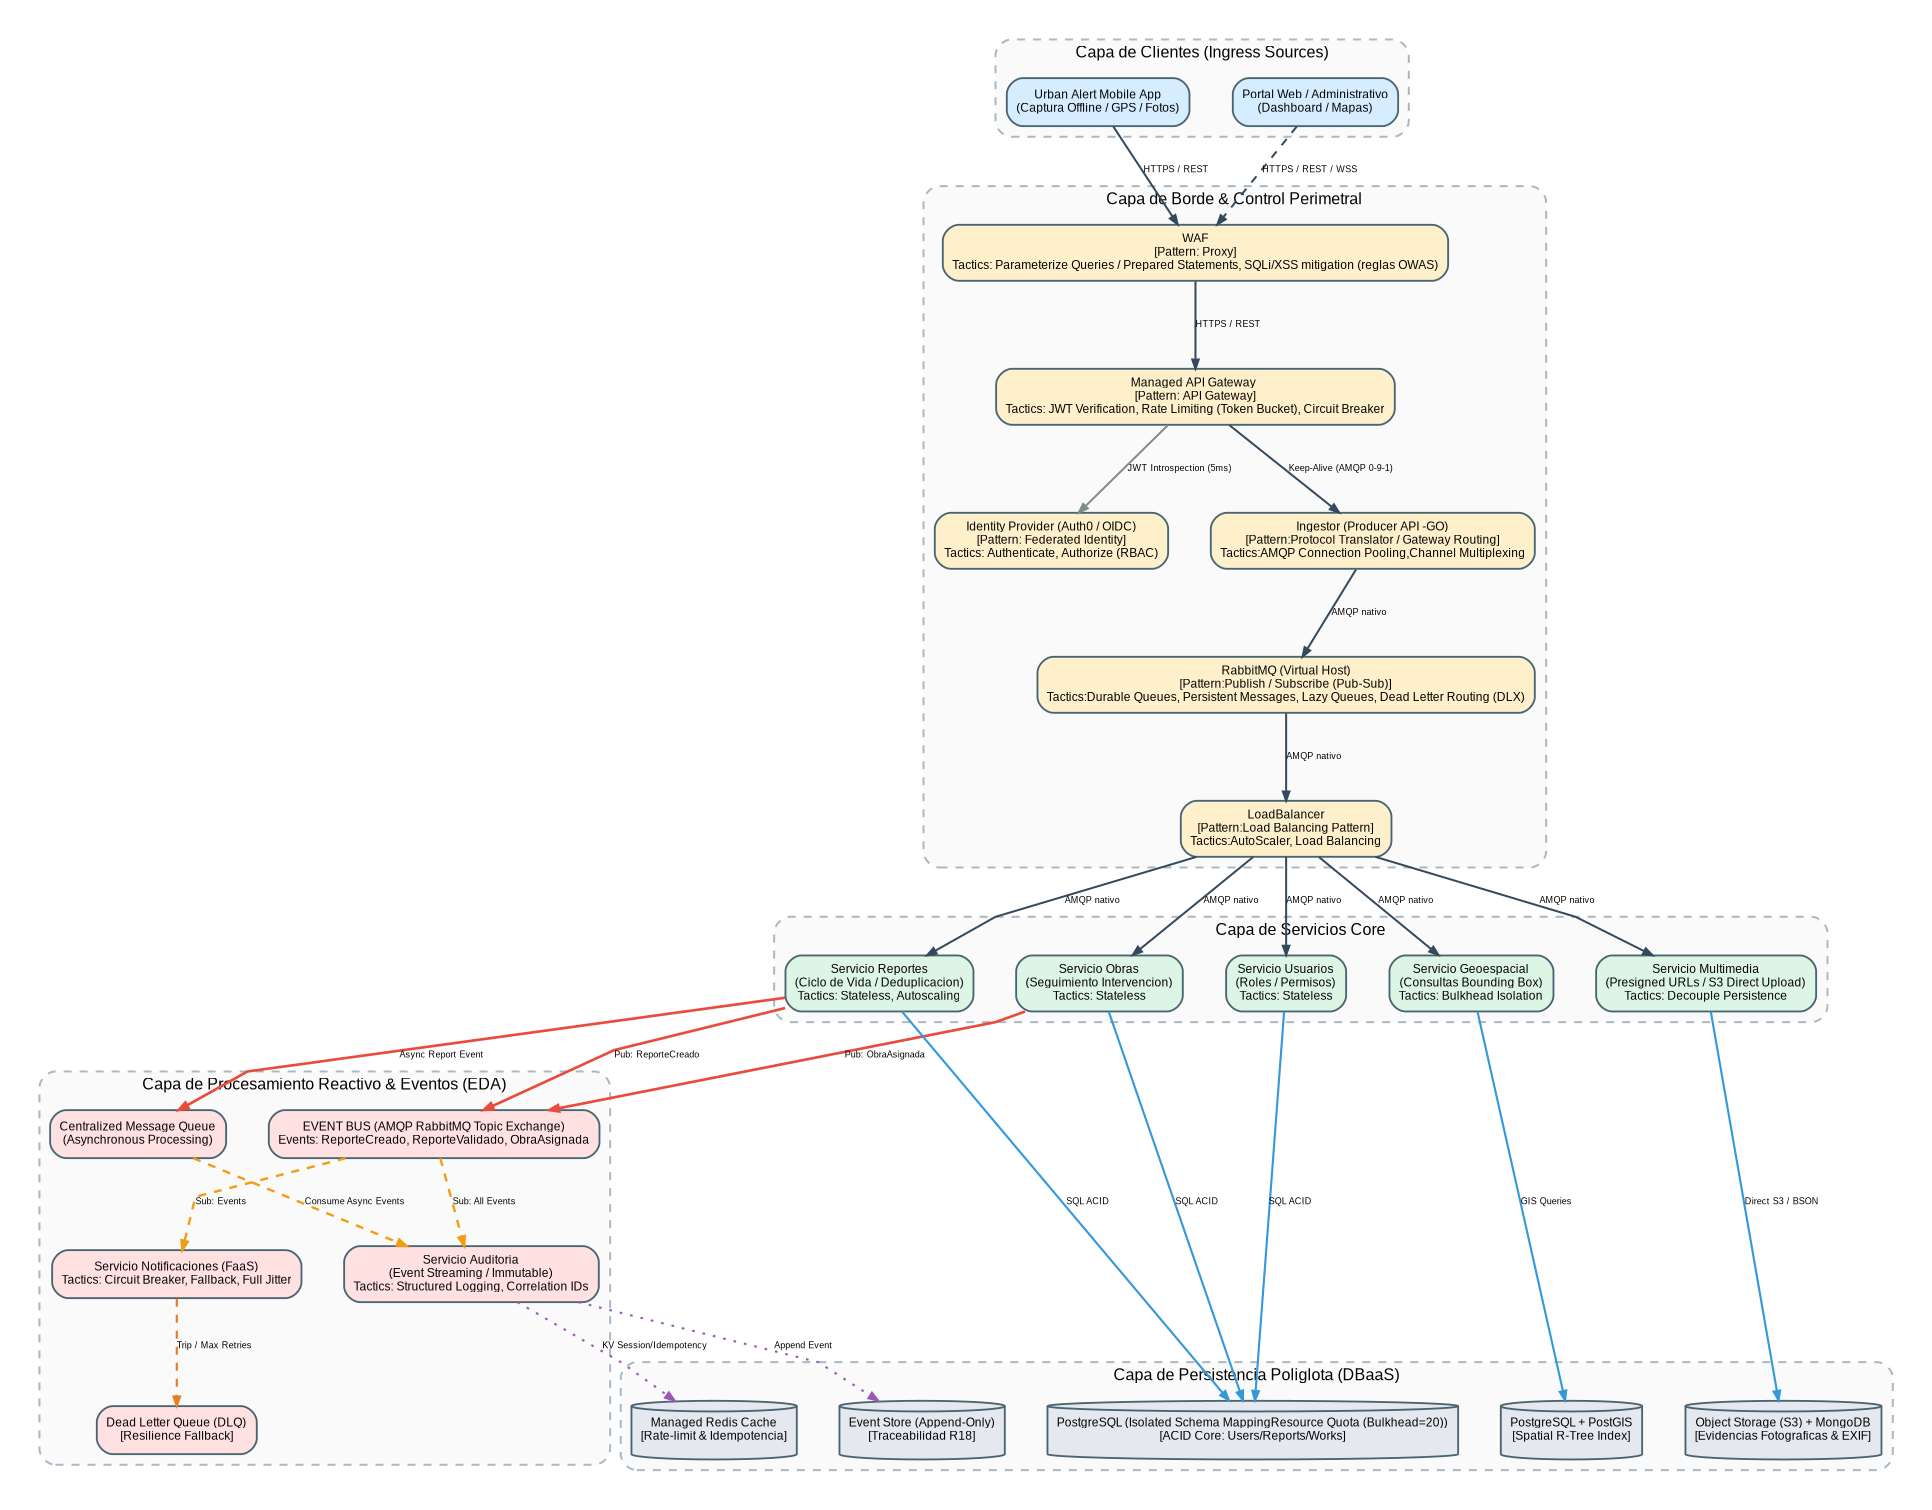

In [ ]:
# ============================================================
# 8. EJECUCIÓN
# ============================================================

analizar_arquitectura(model)

archivo_png = graficar_arquitectura(
    model,
    "arquitectura_imagen"
)


# ============================================================
# 9. MOSTRAR IMAGEN EN GOOGLE COLAB
# ============================================================

display(Image(filename=archivo_png))

# Metamodelo: Quality Attributes, Quality Scenarios, Patterns y Tactics

Esta sección representa el metamodelo de calidad, patrones y tácticas sobre el DSL de arquitectura definido arriba. Todos los conceptos heredan de `Element` (`name`, `description`).

```text
Element
├── Component
├── Connector
├── Interface
├── Port
├── ComponentType
├── ConnectorType
├── Pattern
├── Tactic
├── QualityAttribute
└── QualityScenario

QualityAttribute
    ├── name
    ├── description
    ├── category
    └── subAttribute

QualityScenario
    ├── source
    ├── stimulus
    ├── environment
    ├── artifact
    ├── response
    └── responseMeasure

Tactic
├── name
├── description
├── rationale
├── mechanism
├── preconditions
└── consequences

Tactic ──addresses──> QualityAttribute
Tactic ──appliesTo──> Component
Tactic ──appliesTo──> Connector
Tactic ──refines──> Pattern
Tactic ──conflictsWith──> Tactic
Tactic ──complements──> Tactic

Pattern
├── name
├── intent
├── context
├── problem
├── solution
├── consequences
├── forces
└── applicability

Pattern ──addresses──> QualityAttribute
Pattern ──composedOf──> Tactic
Pattern ──uses──> Pattern
Pattern ──realizedBy──> Component
Pattern ──realizedBy──> Connector
Pattern ──constrains──> Component
```

**Convenciones de implementación**

- Cada concepto es una clase Python (`dataclass`) que hereda de `Element`.
- Los nombres camelCase de la especificación se escriben en snake_case en el código: `subAttribute` → `sub_attributes`, `responseMeasure` → `response_measure`, `appliesTo` → `applies_to`, `composedOf` → `composed_of`, etc.
- Cada relación es un atributo de lista en la clase de origen (por ejemplo, `Tactic.addresses`) y está registrada en un catálogo (`RELATIONS`) que permite validar los tipos de destino.
- `QualityScenario.quality_attribute` es un vínculo que ya existía en el notebook original; no forma parte de la especificación, pero permite saber qué atributo concreta cada escenario.

In [5]:
from __future__ import annotations

from dataclasses import dataclass, field
from typing import List, Optional, Union


def elemento(cls):
    """Dataclass con identidad por referencia (eq=False) y repr compacto.

    Las relaciones entre tácticas y patrones pueden ser cíclicas
    (p. ej. conflictsWith), por lo que una comparación o un repr estructural
    entraría en recursión infinita.
    """
    return dataclass(eq=False, repr=False)(cls)


# ============================================================
# Element (raíz del metamodelo)
# ============================================================

@elemento
class Element:
    name: str
    description: str = ""

    def __repr__(self):
        return f"{type(self).__name__}({self.name!r})"


# ============================================================
# Estructura: Component, Connector, Interface, Port y sus tipos
# ============================================================

@elemento
class Component(Element):
    component_type: Optional[ComponentType] = None
    interfaces: List[Interface] = field(default_factory=list)
    ports: List[Port] = field(default_factory=list)


@elemento
class Connector(Element):
    connector_type: Optional[ConnectorType] = None
    source: Optional[Component] = None
    target: Optional[Component] = None


@elemento
class Interface(Element):
    operations: List[str] = field(default_factory=list)


@elemento
class Port(Element):
    direction: str = "provided"          # provided | required
    interface: Optional[Interface] = None


@elemento
class ComponentType(Element):
    pass


@elemento
class ConnectorType(Element):
    pass


# ============================================================
# Pattern
# ============================================================

@elemento
class Pattern(Element):
    intent: str = ""
    context: str = ""
    problem: str = ""
    solution: str = ""
    consequences: List[str] = field(default_factory=list)
    forces: List[str] = field(default_factory=list)
    applicability: str = ""
    # --- relaciones ---
    addresses: List[QualityAttribute] = field(default_factory=list)      # addresses   -> QualityAttribute
    composed_of: List[Tactic] = field(default_factory=list)              # composedOf  -> Tactic
    uses: List[Pattern] = field(default_factory=list)                    # uses        -> Pattern
    realized_by: List[Union[Component, Connector]] = field(default_factory=list)  # realizedBy -> Component | Connector
    constrains: List[Component] = field(default_factory=list)            # constrains  -> Component


# ============================================================
# Tactic
# ============================================================

@elemento
class Tactic(Element):
    rationale: str = ""
    mechanism: str = ""
    preconditions: List[str] = field(default_factory=list)
    consequences: List[str] = field(default_factory=list)
    # --- relaciones ---
    addresses: List[QualityAttribute] = field(default_factory=list)      # addresses     -> QualityAttribute
    applies_to: List[Union[Component, Connector]] = field(default_factory=list)  # appliesTo -> Component | Connector
    refines: List[Pattern] = field(default_factory=list)                 # refines       -> Pattern
    conflicts_with: List[Tactic] = field(default_factory=list)           # conflictsWith -> Tactic
    complements: List[Tactic] = field(default_factory=list)              # complements   -> Tactic


# ============================================================
# Calidad
# ============================================================

@elemento
class QualityAttribute(Element):
    category: str = ""
    sub_attributes: List[QualityAttribute] = field(default_factory=list)


@elemento
class QualityScenario(Element):
    source: str = ""
    stimulus: str = ""
    environment: str = ""
    artifact: str = ""
    response: str = ""
    response_measure: str = ""
    # Vínculo conservado del notebook original (no forma parte de la especificación):
    # indica qué atributo de calidad concreta el escenario.
    quality_attribute: Optional[QualityAttribute] = None

## Catálogo de relaciones

Las relaciones de `Tactic` y `Pattern` se declaran una sola vez en `RELATIONS` (origen, nombre, atributo y tipos de destino permitidos). El catálogo se usa para imprimirlas y para validar cualquier instancia con `validar_modelo`.

In [6]:
from collections import namedtuple

Relacion = namedtuple("Relacion", "origen nombre atributo destinos")

RELATIONS = [
    # Tactic
    Relacion(Tactic,  "addresses",     "addresses",      (QualityAttribute,)),
    Relacion(Tactic,  "appliesTo",     "applies_to",     (Component, Connector)),
    Relacion(Tactic,  "refines",       "refines",        (Pattern,)),
    Relacion(Tactic,  "conflictsWith", "conflicts_with", (Tactic,)),
    Relacion(Tactic,  "complements",   "complements",    (Tactic,)),
    # Pattern
    Relacion(Pattern, "addresses",     "addresses",      (QualityAttribute,)),
    Relacion(Pattern, "composedOf",    "composed_of",    (Tactic,)),
    Relacion(Pattern, "uses",          "uses",           (Pattern,)),
    Relacion(Pattern, "realizedBy",    "realized_by",    (Component, Connector)),
    Relacion(Pattern, "constrains",    "constrains",     (Component,)),
]


def imprimir_catalogo_relaciones():
    origen_previo = None
    for r in RELATIONS:
        if origen_previo and r.origen is not origen_previo:
            print()
        origen_previo = r.origen
        for destino in r.destinos:
            print(f"{r.origen.__name__:8} ──{r.nombre}──> {destino.__name__}")


def validar_modelo(elementos):
    """Comprueba que cada relación apunte a instancias del tipo permitido
    y que no haya tácticas a la vez en conflicto y en complemento."""
    errores = []

    for el in elementos:
        for r in RELATIONS:
            if not isinstance(el, r.origen):
                continue
            for destino in getattr(el, r.atributo):
                if not isinstance(destino, r.destinos):
                    esperado = " | ".join(d.__name__ for d in r.destinos)
                    errores.append(
                        f"{el!r} ──{r.nombre}──> {destino!r}: "
                        f"se esperaba {esperado}, se recibió {type(destino).__name__}"
                    )

        if isinstance(el, Tactic):
            for otra in el.conflicts_with:
                if otra in el.complements:
                    errores.append(
                        f"{el!r} y {otra!r} están a la vez en conflictsWith y complements"
                    )

    return errores


imprimir_catalogo_relaciones()

Tactic   ──addresses──> QualityAttribute
Tactic   ──appliesTo──> Component
Tactic   ──appliesTo──> Connector
Tactic   ──refines──> Pattern
Tactic   ──conflictsWith──> Tactic
Tactic   ──complements──> Tactic

Pattern  ──addresses──> QualityAttribute
Pattern  ──composedOf──> Tactic
Pattern  ──uses──> Pattern
Pattern  ──realizedBy──> Component
Pattern  ──realizedBy──> Connector
Pattern  ──constrains──> Component


## Verificación de la estructura

Las siguientes celdas generan el árbol de clases, los atributos y las relaciones **a partir del código**, de modo que la representación no puede desviarse del metamodelo implementado. El diagrama distingue las relaciones de `Tactic` (naranja), las de `Pattern` (azul) y las referencias estructurales entre clases (gris punteado).

In [7]:
REL_ATTRS = {(r.origen, r.atributo) for r in RELATIONS}

# Atributos que el notebook conserva aunque no figuran en la especificación.
NOTAS = {"quality_attribute": "   (vínculo adicional al atributo de calidad)"}


def atributos_propios(cls):
    """Atributos declarados en la clase (sin heredados y sin relaciones)."""
    return [a for a in cls.__annotations__ if (cls, a) not in REL_ATTRS]


def relaciones_propias(cls):
    return [r for r in RELATIONS if r.origen is cls]


def imprimir_metamodelo():
    hijos = Element.__subclasses__()

    print("Element  (name, description)")
    for i, cls in enumerate(hijos):
        print(("└── " if i == len(hijos) - 1 else "├── ") + cls.__name__)

    for cls in hijos:
        atributos = ["name", "description"] + atributos_propios(cls)
        print(f"\n{cls.__name__}")
        for i, a in enumerate(atributos):
            rama = "└── " if i == len(atributos) - 1 else "├── "
            print(f"{rama}{a}{NOTAS.get(a, '')}")

        relaciones = relaciones_propias(cls)
        if relaciones:
            print()
            for r in relaciones:
                for destino in r.destinos:
                    print(f"{cls.__name__} ──{r.nombre}──> {destino.__name__}")


imprimir_metamodelo()

Element  (name, description)
├── Component
├── Connector
├── Interface
├── Port
├── ComponentType
├── ConnectorType
├── Pattern
├── Tactic
├── QualityAttribute
└── QualityScenario

Component
├── name
├── description
├── component_type
├── interfaces
└── ports

Connector
├── name
├── description
├── connector_type
├── source
└── target

Interface
├── name
├── description
└── operations

Port
├── name
├── description
├── direction
└── interface

ComponentType
├── name
└── description

ConnectorType
├── name
└── description

Pattern
├── name
├── description
├── intent
├── context
├── problem
├── solution
├── consequences
├── forces
└── applicability

Pattern ──addresses──> QualityAttribute
Pattern ──composedOf──> Tactic
Pattern ──uses──> Pattern
Pattern ──realizedBy──> Component
Pattern ──realizedBy──> Connector
Pattern ──constrains──> Component

Tactic
├── name
├── description
├── rationale
├── mechanism
├── preconditions
└── consequences

Tactic ──addresses──> QualityAttribute
Tactic ──

Diagrama generado: metamodelo.png


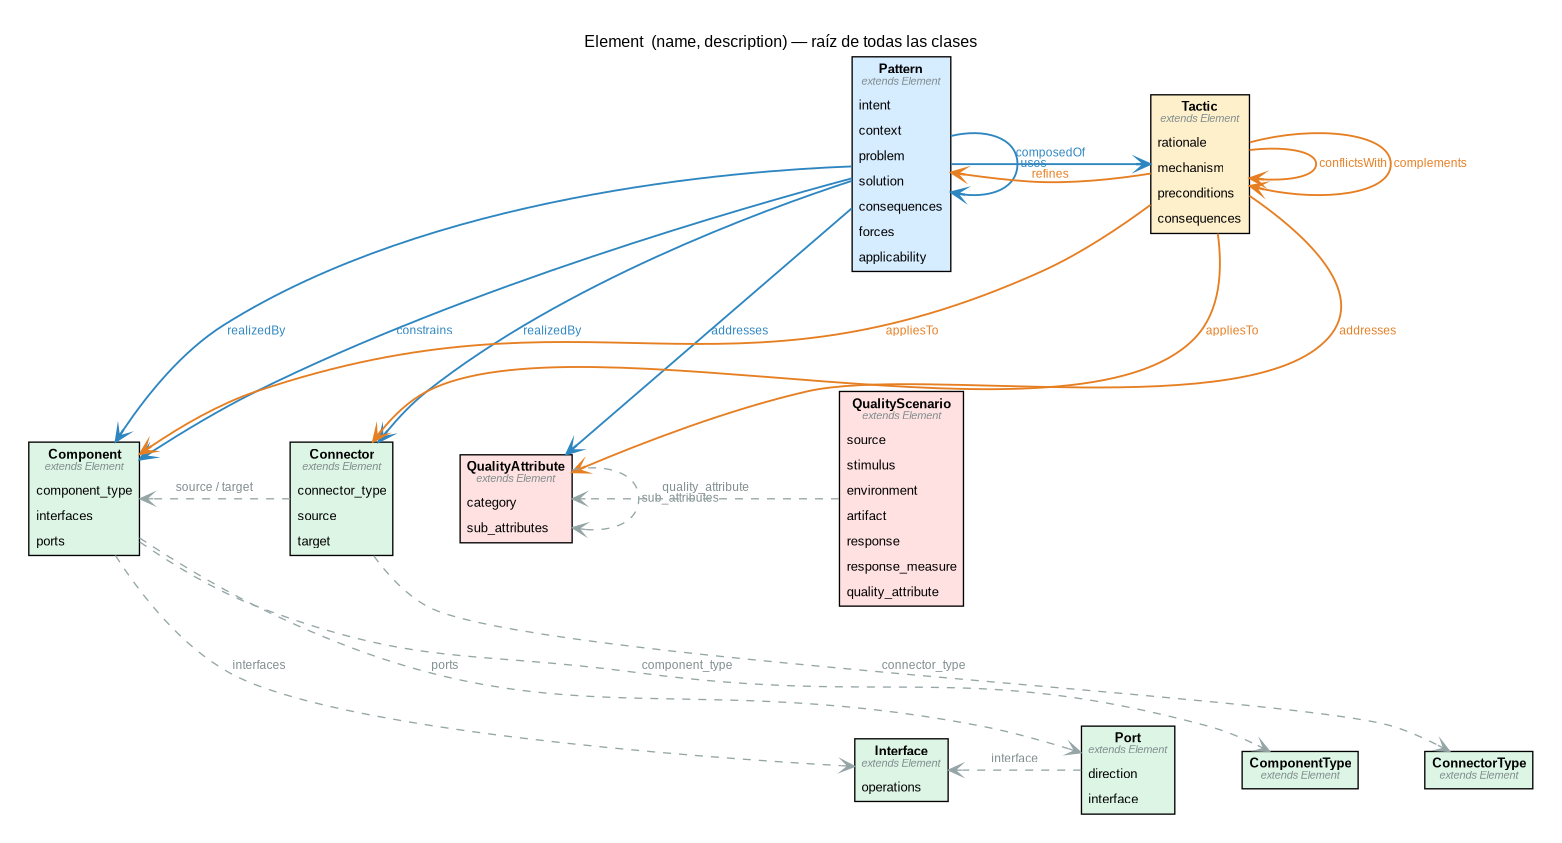

In [8]:
from graphviz import Digraph
from html import escape
from IPython.display import Image, display

COLOR_CLASE = {
    "Component": "#DDF5E5", "Connector": "#DDF5E5", "Interface": "#DDF5E5",
    "Port": "#DDF5E5", "ComponentType": "#DDF5E5", "ConnectorType": "#DDF5E5",
    "Pattern": "#D6ECFF", "Tactic": "#FFF0CC",
    "QualityAttribute": "#FFE1E1", "QualityScenario": "#FFE1E1",
}
COLOR_RELACION = {Pattern: "#2E86C1", Tactic: "#E67E22"}

# Referencias estructurales (atributos que apuntan a otras clases)
REFERENCIAS = [
    ("Component", "Interface", "interfaces"),
    ("Component", "Port", "ports"),
    ("Component", "ComponentType", "component_type"),
    ("Connector", "ConnectorType", "connector_type"),
    ("Connector", "Component", "source / target"),
    ("Port", "Interface", "interface"),
    ("QualityAttribute", "QualityAttribute", "sub_attributes"),
    ("QualityScenario", "QualityAttribute", "quality_attribute"),
]


def _nodo_clase(cls):
    cuerpo = "".join(
        f'<TR><TD ALIGN="LEFT" BORDER="0">{escape(a)}</TD></TR>'
        for a in atributos_propios(cls)
    )
    return (
        '<<TABLE BORDER="1" CELLBORDER="0" CELLSPACING="0" CELLPADDING="4" '
        f'BGCOLOR="{COLOR_CLASE[cls.__name__]}">'
        f'<TR><TD><B>{cls.__name__}</B><BR/>'
        '<FONT POINT-SIZE="8" COLOR="#7F8C8D"><I>extends Element</I></FONT></TD></TR>'
        f'{cuerpo}</TABLE>>'
    )


def graficar_metamodelo(archivo="metamodelo"):
    dot = Digraph(name="Metamodelo", format="png")
    dot.attr(rankdir="TB", bgcolor="white", fontname="Arial", pad="0.3",
             nodesep="0.7", ranksep="1.1", splines="true", newrank="true",
             label="Element  (name, description) — raíz de todas las clases",
             labelloc="t", fontsize="12")
    dot.attr("node", shape="plain", fontname="Arial", fontsize="10")
    dot.attr("edge", fontname="Arial", fontsize="9")

    for cls in Element.__subclasses__():
        dot.node(cls.__name__, label=_nodo_clase(cls))

    # Filas del diagrama (de arriba hacia abajo)
    filas = [
        ["Pattern", "Tactic"],
        ["QualityScenario", "QualityAttribute", "Component", "Connector"],
        ["Interface", "Port", "ComponentType", "ConnectorType"],
    ]
    for fila in filas:
        with dot.subgraph() as s:
            s.attr(rank="same")
            for nombre in fila:
                s.node(nombre)
    for arriba, abajo in zip(filas, filas[1:]):
        dot.edge(arriba[0], abajo[0], style="invis")

    # Referencias estructurales (gris, punteadas)
    for origen, destino, atributo in REFERENCIAS:
        dot.edge(origen, destino, label=f" {atributo} ", style="dashed",
                 color="#95A5A6", fontcolor="#7F8C8D", arrowhead="open",
                 constraint="false")

    # Relaciones de Tactic (naranja) y Pattern (azul)
    for r in RELATIONS:
        color = COLOR_RELACION[r.origen]
        for destino in r.destinos:
            dot.edge(r.origen.__name__, destino.__name__, label=f" {r.nombre} ",
                     color=color, fontcolor=color, penwidth="1.4",
                     arrowhead="vee", constraint="false")

    ruta = dot.render(filename=archivo, cleanup=True)
    print(f"Diagrama generado: {ruta}")
    return ruta


display(Image(graficar_metamodelo("metamodelo")))

## Instancia: Urban Alert

Se toma el modelo textX de la arquitectura (componentes y conectores parseados arriba) y se convierte en instancias del metamodelo. Sobre esos componentes y conectores se declaran atributos de calidad, escenarios, tácticas y patrones.

Los patrones y tácticas provienen de las anotaciones `[Pattern: …]` y `Tactics: …` de las etiquetas del modelo. Los escenarios, los valores de `response_measure` y las relaciones `conflictsWith`, `complements` y `refines` son **ilustrativos** y deben ajustarse a los requisitos reales del proyecto.

In [9]:
import re


def importar_arquitectura(modelo):
    """Convierte el modelo textX (Layer/Component/Connector) en instancias
    del metamodelo: Component, Connector, ComponentType y ConnectorType."""
    tipos_componente, tipos_conector = {}, {}
    componentes, conectores = {}, {}

    for e in modelo.elements:
        if e.__class__.__name__ != "Component":
            continue
        tipo = str(e.type)
        tipos_componente.setdefault(tipo, ComponentType(name=tipo))
        # La primera línea de la etiqueta es la descripción del componente
        descripcion = re.split(r"\\n|\n", e.label)[0]
        componentes[e.name] = Component(
            name=e.name,
            description=descripcion,
            component_type=tipos_componente[tipo],
        )

    for e in modelo.elements:
        if e.__class__.__name__ != "Connector":
            continue
        tipo = str(e.type)
        tipos_conector.setdefault(tipo, ConnectorType(name=tipo))
        origen, destino = componentes[e.source.name], componentes[e.target.name]
        conectores[(origen.name, destino.name)] = Connector(
            name=f"{origen.name}->{destino.name}",
            description=e.label,
            connector_type=tipos_conector[tipo],
            source=origen,
            target=destino,
        )

    return componentes, conectores, list(tipos_componente.values()), list(tipos_conector.values())


componentes, conectores, tipos_componente, tipos_conector = importar_arquitectura(model)

print(f"Componentes:     {len(componentes)}")
print(f"Conectores:      {len(conectores)}")
print(f"ComponentTypes:  {sorted(t.name for t in tipos_componente)}")
print(f"ConnectorTypes:  {sorted(t.name for t in tipos_conector)}")

Componentes:     23
Conectores:      26
ComponentTypes:  ['cache', 'client', 'database', 'event_bus', 'event_store', 'gateway', 'identity', 'microservice', 'object_storage', 'queue', 'reactive_service']
ConnectorTypes:  ['auth', 'cache_access', 'event_append', 'event_publish', 'event_subscribe', 'http', 'object_upload', 'rest', 'retry', 'spatial_query', 'sql', 'websocket']


In [10]:
# Accesos rápidos a los elementos de la arquitectura
C = componentes
def K(origen, destino):
    return conectores[(origen, destino)]

# Interface y Port de ejemplo (API pública del gateway)
api_publica = Interface(name="API pública REST", operations=["POST /reportes", "GET /reportes/{id}"])
C["ApiGateway"].interfaces.append(api_publica)
C["ApiGateway"].ports.append(Port(name="https_in", direction="provided", interface=api_publica))


# ============================================================
# QualityAttribute
# ============================================================

fault_tolerance = QualityAttribute(name="Fault Tolerance", category="Runtime",
    description="Continuar operando ante fallas de dependencias o componentes.")
availability = QualityAttribute(name="Availability", category="Runtime",
    description="Proporción de tiempo en que el sistema atiende solicitudes.",
    sub_attributes=[fault_tolerance])

authentication = QualityAttribute(name="Authentication", category="Runtime",
    description="Verificar la identidad de quien realiza la solicitud.")
authorization = QualityAttribute(name="Authorization", category="Runtime",
    description="Restringir las operaciones según rol y permisos.")
security = QualityAttribute(name="Security", category="Runtime",
    description="Proteger la información y las operaciones frente a accesos indebidos.",
    sub_attributes=[authentication, authorization])

elasticity = QualityAttribute(name="Elasticity", category="Runtime",
    description="Ajustar la capacidad a la demanda de forma automática.")
scalability = QualityAttribute(name="Scalability", category="Runtime",
    description="Atender mayor carga incrementando recursos.",
    sub_attributes=[elasticity])

performance = QualityAttribute(name="Performance", category="Runtime",
    description="Responder dentro de los tiempos requeridos.")
auditability = QualityAttribute(name="Auditability", category="Compliance",
    description="Trazabilidad inmutable de los eventos del sistema (R18).")

atributos = [availability, fault_tolerance, security, authentication, authorization,
             scalability, elasticity, performance, auditability]


# ============================================================
# QualityScenario  (valores de medida ilustrativos)
# ============================================================

escenarios = [
    QualityScenario(
        name="QS-01 Falla del proveedor de notificaciones",
        source="Proveedor externo de notificaciones",
        stimulus="Responde con errores o timeouts de forma sostenida",
        environment="Operación normal",
        artifact="ServicioNotificaciones",
        response="Abre el circuit breaker, reintenta con full jitter y deriva los mensajes fallidos a la DLQ",
        response_measure="0 eventos perdidos; sin degradación en el resto de servicios",
        quality_attribute=fault_tolerance),
    QualityScenario(
        name="QS-02 Ataque de inyección",
        source="Atacante externo",
        stimulus="Envía solicitudes con payloads SQLi/XSS",
        environment="Operación normal",
        artifact="WAF",
        response="Bloquea la solicitud antes de llegar al API Gateway y registra el intento",
        response_measure="100 % de los payloads cubiertos por las reglas OWASP bloqueados",
        quality_attribute=security),
    QualityScenario(
        name="QS-03 Pico de reportes ciudadanos",
        source="Ciudadanos (App Móvil)",
        stimulus="Ráfaga de reportes concurrentes",
        environment="Sobrecarga",
        artifact="LoadBalancer / ServicioReportes",
        response="Escala instancias stateless y distribuye la carga",
        response_measure="Latencia p95 < 500 ms (valor ilustrativo)",
        quality_attribute=scalability),
]


# ============================================================
# Tactic
# ============================================================

rate_limiting = Tactic(
    name="Rate Limiting (Token Bucket)",
    description="Limitar la tasa de solicitudes admitidas por cliente.",
    rationale="Proteger los servicios internos de ráfagas y abuso.",
    mechanism="Token bucket por cliente en el gateway; contadores compartidos en Managed Redis.",
    preconditions=["Cliente identificable (JWT)", "Almacén compartido de contadores"],
    consequences=["Rechaza tráfico legítimo en picos (HTTP 429)", "Exige calibrar los límites"],
    addresses=[availability, security],
    applies_to=[C["ApiGateway"]])

circuit_breaker = Tactic(
    name="Circuit Breaker",
    description="Fallar rápido cuando una dependencia está degradada.",
    rationale="Evitar que la falla de una dependencia se propague en cascada.",
    mechanism="Monitorea errores/timeouts, abre el circuito y sondea en half-open.",
    preconditions=["Umbrales de error y timeout definidos", "Fallback disponible"],
    consequences=["Rechaza llamadas mientras está abierto", "Requiere monitoreo del estado del circuito"],
    addresses=[fault_tolerance],
    applies_to=[C["ApiGateway"], C["ServicioNotificaciones"]])

retry_full_jitter = Tactic(
    name="Retry with Full Jitter",
    description="Reintentar con espera exponencial aleatorizada.",
    rationale="Recuperarse de fallos transitorios sin sincronizar los reintentos.",
    mechanism="Espera aleatoria entre 0 y el backoff exponencial antes de cada reintento.",
    preconditions=["Operación idempotente", "Máximo de reintentos definido"],
    consequences=["Mayor latencia en la recuperación", "Puede amplificar la carga si no se limita"],
    addresses=[fault_tolerance],
    applies_to=[K("ServicioNotificaciones", "DeadLetterQueue")])

durable_queues = Tactic(
    name="Durable Queues & Persistent Messages",
    description="Persistir colas y mensajes en disco.",
    rationale="No perder mensajes ante reinicios del broker.",
    mechanism="Colas durables y mensajes marcados como persistentes en RabbitMQ.",
    preconditions=["Broker con almacenamiento persistente"],
    consequences=["Mayor latencia por escritura en disco"],
    addresses=[fault_tolerance],
    applies_to=[C["RabbitMQ"]])

dead_letter_routing = Tactic(
    name="Dead Letter Routing (DLX)",
    description="Desviar los mensajes que agotan reintentos a una cola aparte.",
    rationale="Aislar mensajes problemáticos sin bloquear el flujo principal.",
    mechanism="Dead Letter Exchange que enruta a la DLQ tras el máximo de reintentos.",
    preconditions=["Política de reintentos definida"],
    consequences=["Requiere procesar y revisar la DLQ"],
    addresses=[fault_tolerance],
    applies_to=[C["RabbitMQ"], K("ServicioNotificaciones", "DeadLetterQueue")])

autoscaling = Tactic(
    name="Autoscaling",
    description="Ajustar el número de instancias según la carga.",
    rationale="Absorber picos de demanda sin sobredimensionar de forma permanente.",
    mechanism="Reglas de escalado horizontal sobre métricas de carga.",
    preconditions=["Servicios stateless", "Métricas de carga disponibles"],
    consequences=["Latencia de arranque de instancias", "Costo variable"],
    addresses=[elasticity, performance],
    applies_to=[C["LoadBalancer"], C["ServicioReportes"]])

stateless = Tactic(
    name="Stateless Services",
    description="Mantener el estado fuera de las instancias del servicio.",
    rationale="Permitir que cualquier instancia atienda cualquier solicitud.",
    mechanism="El estado vive en PostgreSQL/Redis; las instancias son intercambiables.",
    preconditions=["Persistencia externa disponible"],
    consequences=["Acceso adicional a almacenes externos"],
    addresses=[scalability],
    applies_to=[C["ServicioObras"], C["ServicioReportes"], C["ServicioUsuarios"]])

parameterize_queries = Tactic(
    name="Parameterize Queries / Prepared Statements",
    description="Separar código SQL de los datos de entrada.",
    rationale="Mitigar inyección SQL.",
    mechanism="Reglas de inspección y consultas parametrizadas.",
    preconditions=["Reglas OWASP actualizadas"],
    consequences=["Posibles falsos positivos"],
    addresses=[security],
    applies_to=[C["WAF"]])

authenticate = Tactic(
    name="Authenticate (JWT / OIDC)",
    description="Verificar la identidad mediante tokens emitidos por el proveedor de identidad.",
    rationale="Centralizar la autenticación fuera de los servicios.",
    mechanism="Introspección/verificación de JWT contra el IdP.",
    preconditions=["Proveedor OIDC disponible"],
    consequences=["Dependencia del IdP para cada solicitud"],
    addresses=[authentication],
    applies_to=[C["IdentityProvider"], K("ApiGateway", "IdentityProvider")])

authorize_rbac = Tactic(
    name="Authorize (RBAC)",
    description="Autorizar operaciones según el rol del usuario.",
    rationale="Aplicar mínimo privilegio.",
    mechanism="Roles y permisos evaluados a partir de los claims del token.",
    preconditions=["Catálogo de roles definido"],
    consequences=["Gestión continua de roles y permisos"],
    addresses=[authorization],
    applies_to=[C["IdentityProvider"], C["ServicioUsuarios"]])

correlation_ids = Tactic(
    name="Structured Logging + Correlation IDs",
    description="Registrar eventos estructurados con identificador de correlación.",
    rationale="Reconstruir el recorrido de una solicitud entre servicios.",
    mechanism="Cada evento propaga un correlation ID y se agrega al Event Store inmutable.",
    preconditions=["Propagación del ID en todos los servicios"],
    consequences=["Mayor volumen de almacenamiento"],
    addresses=[auditability],
    applies_to=[C["ServicioAuditoria"], K("ServicioAuditoria", "EventStore")])

tacticas = [rate_limiting, circuit_breaker, retry_full_jitter, durable_queues,
            dead_letter_routing, autoscaling, stateless, parameterize_queries,
            authenticate, authorize_rbac, correlation_ids]


# Relaciones simétricas: se registran en ambos sentidos
def complementar(a, b):
    a.complements.append(b); b.complements.append(a)

def contradecir(a, b):
    a.conflicts_with.append(b); b.conflicts_with.append(a)

complementar(circuit_breaker, retry_full_jitter)   # el breaker corta lo que el retry insiste en repetir
complementar(retry_full_jitter, dead_letter_routing)
complementar(stateless, autoscaling)               # stateless habilita el escalado horizontal
contradecir(rate_limiting, autoscaling)            # limitar tráfico vs. absorberlo escalando


# ============================================================
# Pattern
# ============================================================

federated_identity = Pattern(
    name="Federated Identity",
    intent="Delegar la autenticación en un proveedor de identidad externo.",
    context="Múltiples clientes y servicios que necesitan identificar al usuario.",
    problem="Implementar autenticación en cada servicio duplica lógica y amplía la superficie de ataque.",
    solution="Un IdP (OIDC) emite tokens que el gateway verifica antes de enrutar la solicitud.",
    forces=["Seguridad centralizada vs. dependencia de un tercero"],
    consequences=["Autenticación única y consistente", "El IdP pasa a ser dependencia crítica"],
    applicability="Sistemas con varios clientes y servicios que comparten usuarios.",
    composed_of=[authenticate, authorize_rbac],
    addresses=[security],
    realized_by=[C["IdentityProvider"], K("ApiGateway", "IdentityProvider")])

api_gateway = Pattern(
    name="API Gateway",
    intent="Ofrecer un punto de entrada único que centraliza seguridad y control de tráfico.",
    context="Clientes móviles y web que consumen varios servicios internos.",
    problem="Exponer los servicios directamente acopla a los clientes con la topología interna y duplica preocupaciones transversales.",
    solution="Un gateway gestionado verifica JWT, aplica rate limiting y circuit breaker, y enruta hacia el Ingestor.",
    forces=["Control perimetral vs. latencia añadida", "Simplicidad para el cliente vs. punto único de falla"],
    consequences=["Entrada única y observable", "Debe ser altamente disponible"],
    applicability="Sistemas con varios clientes detrás de un mismo dominio.",
    composed_of=[rate_limiting, circuit_breaker],
    addresses=[security, availability],
    uses=[federated_identity],
    realized_by=[C["ApiGateway"], K("ApiGateway", "Ingestor")],
    constrains=[C["Ingestor"]])          # el Ingestor solo se accede a través del gateway

proxy = Pattern(
    name="Proxy (WAF)",
    intent="Interponer un intermediario que inspecciona el tráfico antes de llegar al sistema.",
    context="Servicios expuestos a Internet.",
    problem="Las solicitudes maliciosas llegan hasta la lógica de negocio.",
    solution="Un WAF filtra las solicitudes (SQLi/XSS) antes de reenviarlas al API Gateway.",
    forces=["Inspección profunda vs. latencia", "Falsos positivos vs. cobertura"],
    consequences=["Reduce la superficie de ataque", "Añade un salto de red"],
    applicability="Endpoints públicos con requisitos de seguridad perimetral.",
    composed_of=[parameterize_queries],
    addresses=[security],
    realized_by=[C["WAF"]],
    constrains=[C["ApiGateway"]])        # todo el tráfico entrante pasa primero por el WAF

pub_sub = Pattern(
    name="Publish / Subscribe",
    intent="Desacoplar productores y consumidores mediante eventos.",
    context="Servicios que reaccionan a hechos del dominio (ReporteCreado, ObraAsignada).",
    problem="Las llamadas síncronas acoplan a los servicios y propagan fallas.",
    solution="Los servicios publican eventos en un bus/broker AMQP y los consumidores se suscriben a los que les interesan.",
    forces=["Desacoplamiento vs. consistencia eventual", "Durabilidad vs. latencia"],
    consequences=["Consumidores independientes", "Trazabilidad más compleja"],
    applicability="Arquitecturas orientadas a eventos con múltiples consumidores.",
    composed_of=[durable_queues],
    addresses=[fault_tolerance, scalability],
    realized_by=[C["RabbitMQ"], C["EventBus"],
                 K("ServicioReportes", "EventBus"), K("ServicioObras", "EventBus"),
                 K("EventBus", "ServicioNotificaciones"), K("EventBus", "ServicioAuditoria")],
    constrains=[C["ServicioNotificaciones"], C["ServicioAuditoria"]])  # solo consumen eventos

load_balancing = Pattern(
    name="Load Balancing",
    intent="Distribuir la carga entre instancias equivalentes.",
    context="Servicios con demanda variable y múltiples instancias.",
    problem="Una sola instancia se satura ante picos de carga.",
    solution="Un balanceador reparte las solicitudes entre instancias que escalan según la demanda.",
    forces=["Utilización de recursos vs. costo", "Estado local vs. intercambiabilidad de instancias"],
    consequences=["Escalado horizontal", "El balanceador es un punto crítico"],
    applicability="Servicios stateless con carga variable.",
    composed_of=[autoscaling, stateless],
    addresses=[scalability, performance],
    realized_by=[C["LoadBalancer"], K("LoadBalancer", "ServicioReportes")],
    constrains=[C["ServicioReportes"]])  # debe ser stateless

# Refinamiento: DLX especializa el manejo de fallas del patrón Pub/Sub
dead_letter_routing.refines.append(pub_sub)

patrones = [federated_identity, api_gateway, proxy, pub_sub, load_balancing]

print(f"QualityAttributes: {len(atributos)}   QualityScenarios: {len(escenarios)}   "
      f"Tactics: {len(tacticas)}   Patterns: {len(patrones)}")

QualityAttributes: 9   QualityScenarios: 3   Tactics: 11   Patterns: 5


In [11]:
# ============================================================
# Validación de tipos de relación
# ============================================================

modelo_completo = [
    *componentes.values(), *conectores.values(),
    *tipos_componente, *tipos_conector, api_publica,
    *atributos, *escenarios, *tacticas, *patrones,
]

errores = validar_modelo(modelo_completo)
print("Validación del modelo:", "OK, sin errores" if not errores else f"{len(errores)} errores")
for e in errores:
    print("  -", e)

# Prueba negativa: una relación con destino de tipo incorrecto debe detectarse
tactica_invalida = Tactic(name="Táctica inválida", addresses=[C["ApiGateway"]],
                          applies_to=[availability])
print("\nPrueba negativa:")
for e in validar_modelo([tactica_invalida]):
    print("  -", e)

Validación del modelo: OK, sin errores

Prueba negativa:
  - Tactic('Táctica inválida') ──addresses──> Component('ApiGateway'): se esperaba QualityAttribute, se recibió Component
  - Tactic('Táctica inválida') ──appliesTo──> QualityAttribute('Availability'): se esperaba Component | Connector, se recibió QualityAttribute


## Trazabilidad

Recorrido `QualityAttribute → Pattern → Tactic → Component/Connector`. Un atributo sin patrones o tácticas asociados aparece explícitamente como una brecha.

In [12]:
def alcance(qa):
    """El atributo y todos sus sub-atributos."""
    resultado = [qa]
    for sub in qa.sub_attributes:
        resultado += alcance(sub)
    return resultado


def nombres(elementos):
    return ", ".join(e.name for e in elementos)


def reporte_trazabilidad(raices):
    print("=" * 70)
    print("TRAZABILIDAD: QualityAttribute → Pattern → Tactic → Component/Connector")
    print("=" * 70)

    for qa in raices:
        ambito = alcance(qa)
        print(f"\n■ {qa.name}  [{qa.category}]"
              + (f"  (sub: {nombres(qa.sub_attributes)})" if qa.sub_attributes else ""))

        for esc in escenarios:
            if esc.quality_attribute in ambito:
                print(f"   Scenario : {esc.name}  →  {esc.response_measure}")

        patrones_qa = [p for p in patrones if any(a in ambito for a in p.addresses)]
        tacticas_qa = [t for t in tacticas if any(a in ambito for a in t.addresses)]

        for p in patrones_qa:
            print(f"   Pattern  : {p.name}")
            for etiqueta, lista in (("realizedBy", p.realized_by),
                                    ("constrains", p.constrains),
                                    ("uses", p.uses)):
                if lista:
                    print(f"       {etiqueta:13}: {nombres(lista)}")
        if not patrones_qa:
            print("   Pattern  : — (sin patrones asociados)")

        for t in tacticas_qa:
            print(f"   Tactic   : {t.name}")
            for etiqueta, lista in (("appliesTo", t.applies_to),
                                    ("refines", t.refines),
                                    ("complements", t.complements),
                                    ("conflictsWith", t.conflicts_with)):
                if lista:
                    print(f"       {etiqueta:13}: {nombres(lista)}")
        if not tacticas_qa:
            print("   Tactic   : — (sin tácticas asociadas)")


reporte_trazabilidad([availability, security, scalability, performance, auditability])

TRAZABILIDAD: QualityAttribute → Pattern → Tactic → Component/Connector

■ Availability  [Runtime]  (sub: Fault Tolerance)
   Scenario : QS-01 Falla del proveedor de notificaciones  →  0 eventos perdidos; sin degradación en el resto de servicios
   Pattern  : API Gateway
       realizedBy   : ApiGateway, ApiGateway->Ingestor
       constrains   : Ingestor
       uses         : Federated Identity
   Pattern  : Publish / Subscribe
       realizedBy   : RabbitMQ, EventBus, ServicioReportes->EventBus, ServicioObras->EventBus, EventBus->ServicioNotificaciones, EventBus->ServicioAuditoria
       constrains   : ServicioNotificaciones, ServicioAuditoria
   Tactic   : Rate Limiting (Token Bucket)
       appliesTo    : ApiGateway
       conflictsWith: Autoscaling
   Tactic   : Circuit Breaker
       appliesTo    : ApiGateway, ServicioNotificaciones
       complements  : Retry with Full Jitter
   Tactic   : Retry with Full Jitter
       appliesTo    : ServicioNotificaciones->DeadLetterQueue
     